# 03 · Data augmentation

**Idea.** Make extra training rows from each training photo by changing it — crops, mirror, colour, zoom, rotation —
so the classifier sees more variety (Shorten & Khoshgoftaar, 2019, *A survey on image data augmentation*).

**Fair testing.** The changed versions of a photo are added only while that photo is on the training side of a split;
the photo being scored never has its own variations in training. (An earlier attempt that augmented first and split
afterwards scored 0.995 — the model just recognised copies of the same photo — while the honest score was about 0.81.)

All views were encoded once with DINOv2 and are cached (`features/*aug*.npz`). 66 competition photos, DINOv2, no
external data.

In [1]:
import numpy as np, pandas as pd
import common as c
pd.set_option('display.width', 200)

In [2]:
df = c.training_set()
X = c.embed(df.id)
ids = df.id.values

def views_from(name, key, take=None, mirror=None):
    z, pos = c._load(name)
    V = z[key]
    if mirror is not None:
        V = c.unit(V + z[mirror])
    V = V[[pos[int(i)] for i in ids]]
    return V if take is None else V[:, take]

z, pos = c._load("dinov2_l")
VIEWS = {
    "5 fixed crops": z["crops"][[pos[int(i)] for i in ids]],
    "5 colour changes": views_from("dinov2_l_color", "color")[:, :, 0],
    "20 random crops": views_from("dinov2_l_aug", "aug"),
    "30 random views (crop, rotate, grey, dark)": views_from("rand_aug_dinov2_l", "img", take=slice(0, 30), mirror="mirror"),
    "4 zooms (in 1.25/1.5, out 0.8/0.67)": views_from("zoom_aug", "dinov2"),
    "13 crop / rotate / colour-swap views": views_from("swap_aug_dinov2_l", "views"),
}
{k: v.shape for k, v in VIEWS.items()}

{'5 fixed crops': (66, 5, 2048),
 '5 colour changes': (66, 5, 2048),
 '20 random crops': (66, 20, 2048),
 '30 random views (crop, rotate, grey, dark)': (66, 30, 2048),
 '4 zooms (in 1.25/1.5, out 0.8/0.67)': (66, 4, 2048),
 '13 crop / rotate / colour-swap views': (66, 13, 2048)}

In [3]:
def extra_rows(V):
    def f(tr):
        return V[tr].reshape(-1, V.shape[-1]), np.repeat(df.y.values[tr], V.shape[1])
    return f

models = ("RBF SVM", "logistic regression")
res = [c.cross_validate(df, X, models, name="no augmentation")[0]]
for name, V in VIEWS.items():
    res.append(c.cross_validate(df, X, models, extra=extra_rows(V), name=name)[0])
res = pd.concat(res)
res.pivot_table(index="experiment", columns="model", values="CV macro F1").round(3)

model,RBF SVM,logistic regression
experiment,,
13 crop / rotate / colour-swap views,0.818,0.815
20 random crops,0.827,0.813
"30 random views (crop, rotate, grey, dark)",0.824,0.820
"4 zooms (in 1.25/1.5, out 0.8/0.67)",0.813,0.807
5 colour changes,0.806,0.816
5 fixed crops,0.814,0.808
no augmentation,0.800,0.808


Example of the 13 crop / rotate / colour-swap views (photo #26): 60% crops from each side turned a different way,
the same crops with colours swapped (red ↔ blue, green ↔ yellow), and the whole photo rotated or colour-swapped.

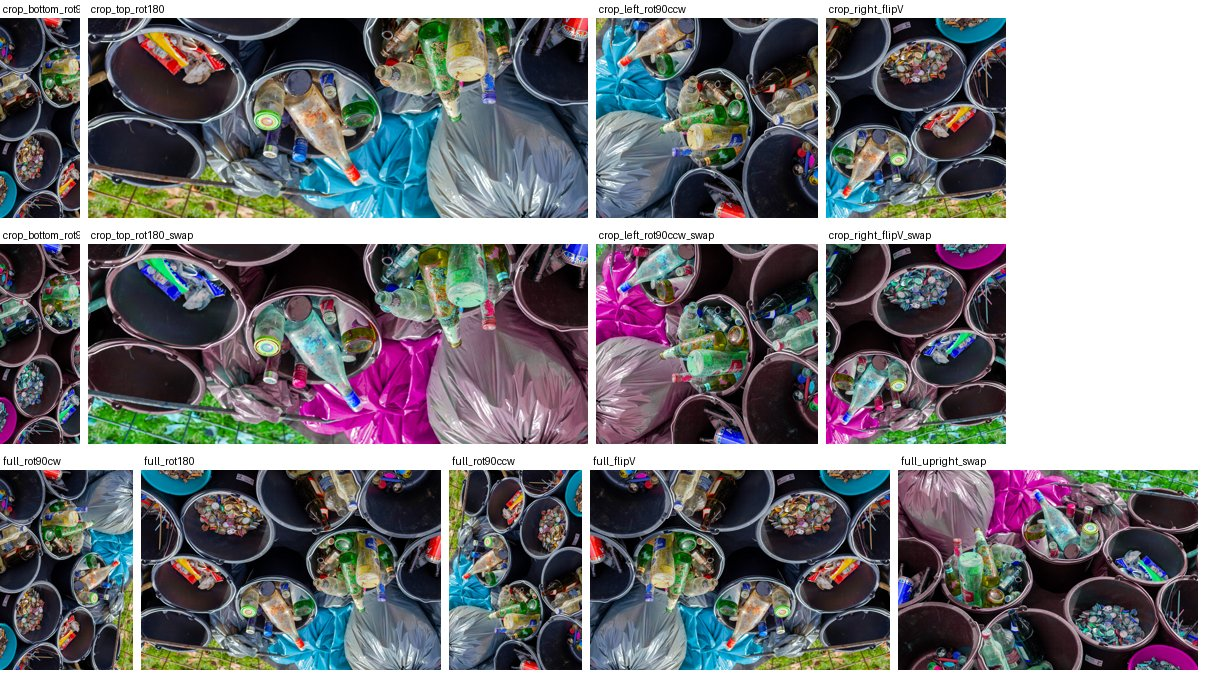

In [4]:
from PIL import Image
Image.open("logs/swap_aug_views_sheet.jpg")

## Does cropping change the label?

A 60% crop can cut the mess out of an *Incomplete* photo, so the crop would carry a wrong label. Check: a model
trained without augmentation predicts the 8 crops of each photo it has not seen. If cropping removed the mess,
crops of Incomplete photos would flip to Complete more often than the photos themselves are misjudged.

In [5]:
V = VIEWS["13 crop / rotate / colour-swap views"][:, :8]          # the 8 crop views
y = df.y.values
photo_wrong, crop_flip = np.zeros(len(df)), np.zeros(len(df))
for tr, va in c.splits(df):
    m = c.MODELS["RBF SVM"]().fit(X[tr], y[tr])
    photo_wrong[va] += c.proba(m, X[va]).argmax(1) != y[va]
    pc = c.proba(m, V[va].reshape(-1, V.shape[-1])).argmax(1).reshape(len(va), -1)
    crop_flip[va] += (pc == (y[va] ^ 1)[:, None]).mean(1)     # predicted as the other completion state
pd.DataFrame({"class": [c.CLASSES[k] for k in y], "photo wrong": photo_wrong / c.REPEATS,
              "crop flipped": crop_flip / c.REPEATS}).groupby("class").mean().round(2)

,photo wrong,crop flipped
class,,
Taking Out Trash|Complete,0.22,0.43
Taking Out Trash|Incomplete,0.15,0.08
Washing Dishes|Complete,0.27,0.30
Washing Dishes|Incomplete,0.15,0.17


**Result.** Augmentation gives at most a small gain. The RBF SVM rises from 0.800 to 0.81–0.83 with every kind of
extra view (best: 20 random crops, +0.027, at the edge of the ±0.02 noise level); logistic regression stays within
±0.01. With external photos and the helpers of notebooks 04–05 the model already scores about 0.91, and earlier runs
showed augmentation did not add to that, so it is not used in the final model.
Crops of *Incomplete* photos do **not** flip to Complete more often than the photos themselves are misjudged
(0.08 vs 0.15 trash, 0.17 vs 0.15 dishes), so cutting away the mess is not the problem; crops of *tidy trash*
photos are the ones that start to look messy (0.43 vs 0.22).